## C1 - WEEK 3

In [3]:
import sys
sys.path.append("..")  # repo root, for utils/
#needed libraries

import os
import re
import cv2
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## TASK 1: Filter noise with linear or non-linear filters

In [4]:
#qsd1 path and results folder
qsd1_path = "./data/qsd1_w3"
results_dir = "./results"
os.makedirs(results_dir, exist_ok=True)

def read_image(img_path):
    image = cv2.imread(img_path)
    if image is None:
        raise IOError(f"Could not read {img_path}")
    return image

#sort files in natural order 
def return_number(string):
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', string)]

qsd1_files = [f for f in os.listdir(qsd1_path) if f.lower().endswith(".jpg")]
qsd1_files.sort(key=return_number)

#query images (some noisy) and their clean version (same file name, non_augmented/ folder)
qsd1_imgs = [read_image(os.path.join(qsd1_path, f)) for f in qsd1_files]
qsd1_clean = [read_image(os.path.join(qsd1_path, "non_augmented", f)) for f in qsd1_files]

#real labels: only used at the end to check the result
with open(os.path.join(qsd1_path, "augmentations.pkl"), "rb") as f:
    qsd1_augs = pickle.load(f)
qsd1_really_noisy = np.array(["Noise" in a for a in qsd1_augs])

First we have to decide which images are noisy and which are not

In [5]:
# Additive noise (a small random value added to each pixel)

LAPLACIAN_DIFF = np.array([[1, -2, 1],
                           [-2, 4, -2],
                           [1, -2, 1]], dtype=np.float64)

def additive_noise(img):
    sigmas = []
    for c in range(img.shape[2]):
        residual = cv2.filter2D(img[..., c].astype(np.float64), -1, LAPLACIAN_DIFF)[1:-1, 1:-1]   #drop the border (padding)
        sigmas.append(np.median(np.abs(residual)) / (0.6745 * 6))
    return np.mean(sigmas)

# Impulse noise (a pixel is replaced by a random value)

T_ISOLATED = 30 #grey levels a pixel must stand out from all its neighbours (~10% of the 0-255 range)
RING = np.ones((3, 3), np.uint8)
RING[1, 1] = 0 #structuring element = the 8 neighbours, without the centre pixel

def impulsive_noise(img, t=T_ISOLATED):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.int16)
    neigh_max = cv2.dilate(gray, RING) #max of the 8 neighbours
    neigh_min = cv2.erode(gray, RING) #min of the 8 neighbours
    return np.mean((gray > neigh_max + t) | (gray < neigh_min - t))

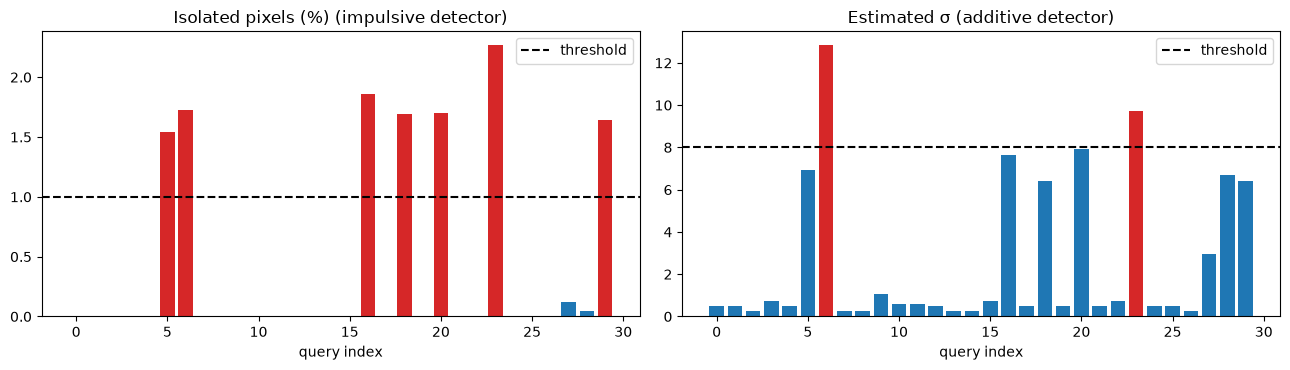

In [6]:
ISOLATED_THRESHOLD = 0.01 #fraction of isolated pixels
SIGMA_THRESHOLD = 8.0 #estimated noise std

qsd1_isolated = np.array([impulsive_noise(img) for img in qsd1_imgs])
qsd1_sigma = np.array([additive_noise(img) for img in qsd1_imgs])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, values, thr, title in [(axes[0], 100 * qsd1_isolated, 100 * ISOLATED_THRESHOLD, "Isolated pixels (%) (impulsive detector)"),
                               (axes[1], qsd1_sigma, SIGMA_THRESHOLD, "Estimated σ (additive detector)")]:
    ax.bar(range(len(values)), values, color=np.where(values > thr, "tab:red", "tab:blue"))
    ax.axhline(thr, ls="--", c="k", label="threshold")
    ax.set_xlabel("query index")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "task1_detector_scores.png"), dpi=120, bbox_inches="tight")
plt.show()

The images only contains impulsive noise, so no image should be classified as additive, and none is: the 23 clean images stay below the threshold, so there are no false alarms. Its ability to detect real additive noise could not be validated, since the dataset has no examples of it, so the threshold (σ = 8) is a fixed value chosen above the σ of clean images, not an optimised one.

Two images (00006 and 00023) exceed the σ threshold even though their noise is impulsive: impulses also increase the estimated σ. This is not an error, since these images are noisy anyway and both detectors simply agree. As the same filter is applied to any noisy image, it does not matter which detector flags it.

In [7]:
def is_noisy(img):
    if impulsive_noise(img) > ISOLATED_THRESHOLD:
        return True
    if additive_noise(img) > SIGMA_THRESHOLD:
        return True
    return False

qsd1_detected = np.array([is_noisy(img) for img in qsd1_imgs])
detected_idx = np.where(qsd1_detected)[0]
print("Detected as noisy:", [qsd1_files[i] for i in detected_idx])

#check with the real labels (only here, never used to decide)
tp = np.sum(qsd1_detected & qsd1_really_noisy)
fp = np.sum(qsd1_detected & ~qsd1_really_noisy)
fn = np.sum(~qsd1_detected & qsd1_really_noisy)
print(f"Correctly detected: {tp}/{qsd1_really_noisy.sum()}")
print(f"False positives: {fp}/{len(qsd1_really_noisy) - qsd1_really_noisy.sum()}")

Detected as noisy: ['00005.jpg', '00006.jpg', '00016.jpg', '00018.jpg', '00020.jpg', '00023.jpg', '00029.jpg']
Correctly detected: 7/7
False positives: 0/23


Now, we are ready to denoise the images detected as noisy. We will try several filters and compare their results. The best one will be used to denoise all the noisy images.

In [8]:
def ideal_lowpass(img, cutoff=0.5):
    h, w = img.shape[:2]
    fy = np.fft.fftshift(np.fft.fftfreq(h))[:, None]
    fx = np.fft.fftshift(np.fft.fftfreq(w))[None, :]
    H = (np.sqrt(fx ** 2 + fy ** 2) <= cutoff * 0.5).astype(np.float64)
    out = np.empty_like(img)
    for c in range(img.shape[2]):
        X = np.fft.fftshift(np.fft.fft2(img[..., c].astype(np.float64)))
        y = np.real(np.fft.ifft2(np.fft.ifftshift(X * H)))
        out[..., c] = np.clip(y, 0, 255)
    return out

SE = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)) #3x3 square structuring element

def open_close(img, se=SE):
    #opening removes small bright points, then closing removes small dark points
    return cv2.morphologyEx(cv2.morphologyEx(img, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)

def close_open(img, se=SE):
    #closing removes small dark points, then opening removes small bright points
    return cv2.morphologyEx(cv2.morphologyEx(img, cv2.MORPH_CLOSE, se), cv2.MORPH_OPEN, se)

FILTERS = {
    #linear, spatial domain
    "average 3x3":         lambda img: cv2.blur(img, (3, 3)),
    "average 5x5":         lambda img: cv2.blur(img, (5, 5)),
    "gaussian 3x3":        lambda img: cv2.GaussianBlur(img, (3, 3), 0),
    "gaussian 5x5":        lambda img: cv2.GaussianBlur(img, (5, 5), 0),
    #linear, frequency domain
    "ideal low-pass 0.5":  lambda img: ideal_lowpass(img, 0.5),
    "ideal low-pass 0.3":  lambda img: ideal_lowpass(img, 0.3),
    #non-linear
    "median 3x3":          lambda img: cv2.medianBlur(img, 3),
    "median 5x5":          lambda img: cv2.medianBlur(img, 5),
    #morphological
    "open-close 3x3":      open_close,
    "close-open 3x3":      close_open,
}

def psnr(ref, img):
    mse = np.mean((ref.astype(np.float64) - img.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

def ssim(ref, img):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    blur = lambda z: cv2.GaussianBlur(z, (11, 11), 1.5)
    values = []
    for c in range(ref.shape[2]):
        x, y = ref[..., c].astype(np.float64), img[..., c].astype(np.float64)
        mu_x, mu_y = blur(x), blur(y)
        var_x = blur(x * x) - mu_x ** 2
        var_y = blur(y * y) - mu_y ** 2
        cov = blur(x * y) - mu_x * mu_y
        ssim_map = ((2 * mu_x * mu_y + C1) * (2 * cov + C2)) / ((mu_x ** 2 + mu_y ** 2 + C1) * (var_x + var_y + C2))
        values.append(ssim_map.mean())
    return np.mean(values)

#mean PSNR and SSIM of every filter on the images detected as noisy
def scores(filter_fn=None):
    out = [img if filter_fn is None else filter_fn(img) for img in (qsd1_imgs[i] for i in detected_idx)]
    ref = [qsd1_clean[i] for i in detected_idx]
    return np.mean([psnr(r, o) for r, o in zip(ref, out)]), np.mean([ssim(r, o) for r, o in zip(ref, out)])

rows = [dict(zip(["Filter", "PSNR (dB)", "SSIM"], ["no filter", *scores()]))]
for name, filter_fn in FILTERS.items():
    rows.append(dict(zip(["Filter", "PSNR (dB)", "SSIM"], [name, *scores(filter_fn)])))

df_psnr = pd.DataFrame(rows).sort_values("PSNR (dB)", ascending=False).reset_index(drop=True)
df_psnr.to_csv(os.path.join(results_dir, "task1_filters_psnr_ssim.csv"), index=False)
display(df_psnr.round(3))

BEST_FILTER = df_psnr.iloc[0]["Filter"]

,Filter,PSNR (dB),SSIM
0,median 3x3,30.778,0.797
1,median 5x5,30.271,0.771
2,gaussian 5x5,29.439,0.768
3,gaussian 3x3,29.116,0.740
4,average 3x3,29.046,0.738
5,average 5x5,28.474,0.723
6,ideal low-pass 0.5,28.276,0.689
7,ideal low-pass 0.3,28.264,0.705
8,open-close 3x3,27.366,0.742
9,close-open 3x3,26.086,0.722


The median 3x3 gives the best result in both PSNR and SSIM, as expected from the theory: it is a non-linear filter that discards outliers (impulses) instead of averaging them into the neighbours.

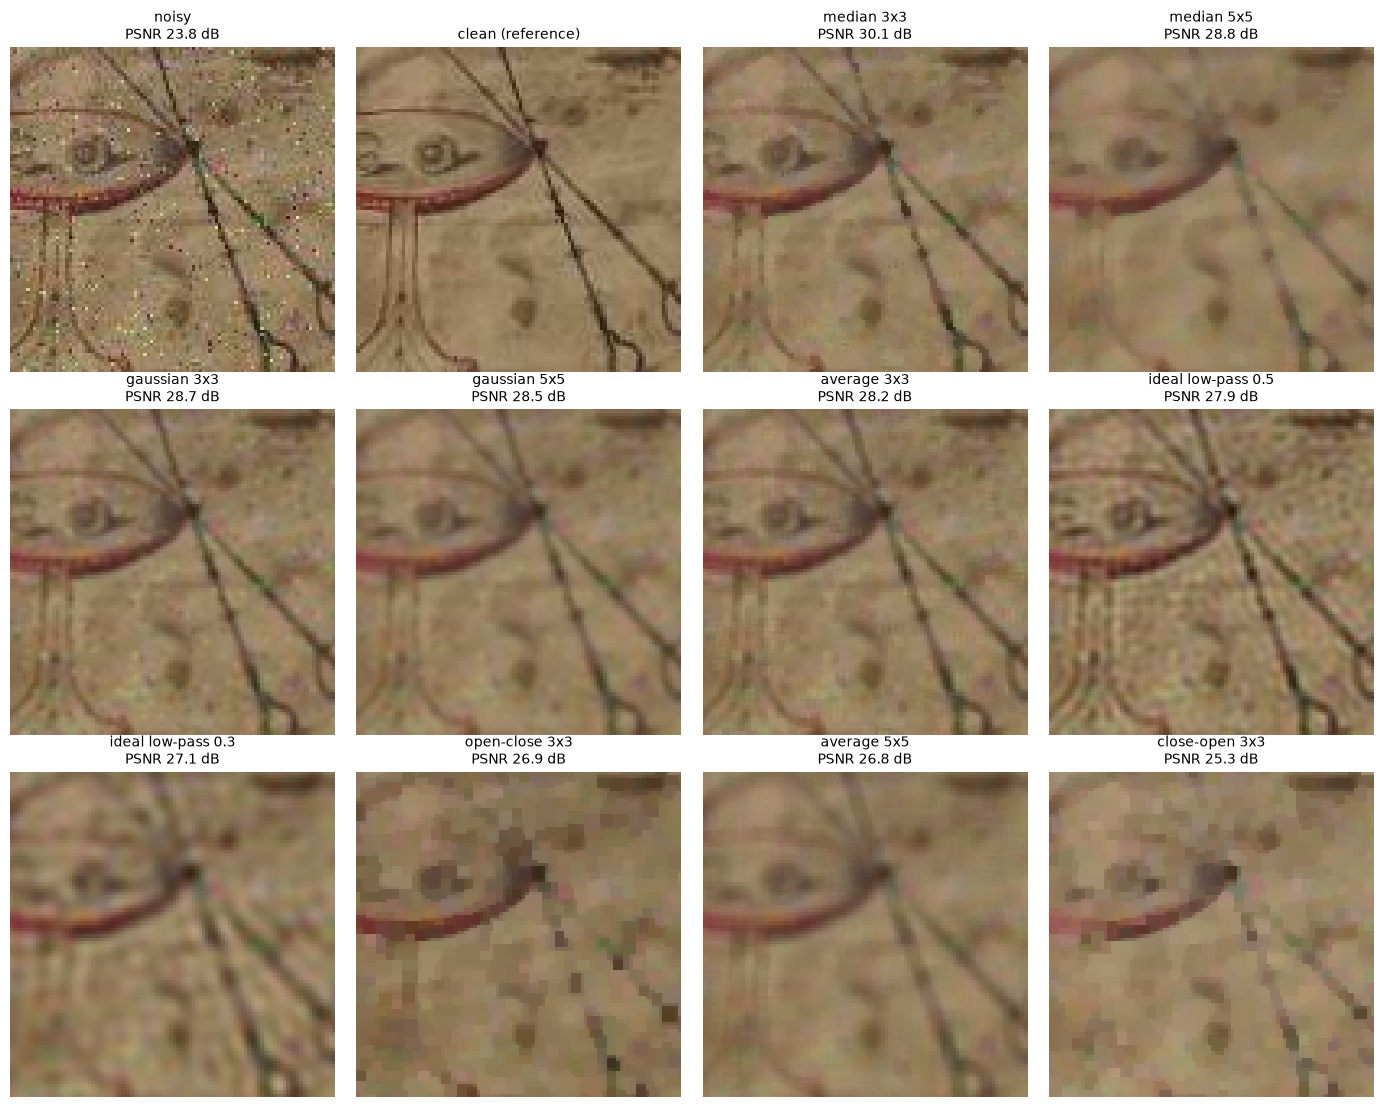

In [9]:
def zoom(img, size=100):
    h, w = img.shape[:2]
    y, x = h // 2 - size // 2, w // 2 - size // 2
    return img[y:y + size, x:x + size]

EXAMPLE = 4

i = detected_idx[EXAMPLE]
panels = [(name, f(qsd1_imgs[i])) for name, f in FILTERS.items()]
panels = [(name, im, psnr(qsd1_clean[i], im)) for name, im in panels]
panels.sort(key=lambda p: p[2], reverse=True)
panels = [("noisy", qsd1_imgs[i], psnr(qsd1_clean[i], qsd1_imgs[i])), ("clean (reference)", qsd1_clean[i], None)] + panels

n_cols = 4
n_rows = int(np.ceil(len(panels) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.5 * n_cols, 3.7 * n_rows))
for rank, (ax, (name, im, value)) in enumerate(zip(axes.flat, panels)):
    ax.imshow(cv2.cvtColor(zoom(im, 100), cv2.COLOR_BGR2RGB), interpolation="nearest")
    ax.set_title(name if value is None else f"{name}\nPSNR {value:.1f} dB", fontsize=10)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(results_dir, f"task1_all_filters_{qsd1_files[i][:-4]}.png"), dpi=120, bbox_inches="tight")
plt.show()

In [10]:
def denoise(img):
    return FILTERS[BEST_FILTER](img) if is_noisy(img) else img

qsd1_denoised = [denoise(img) for img in qsd1_imgs]

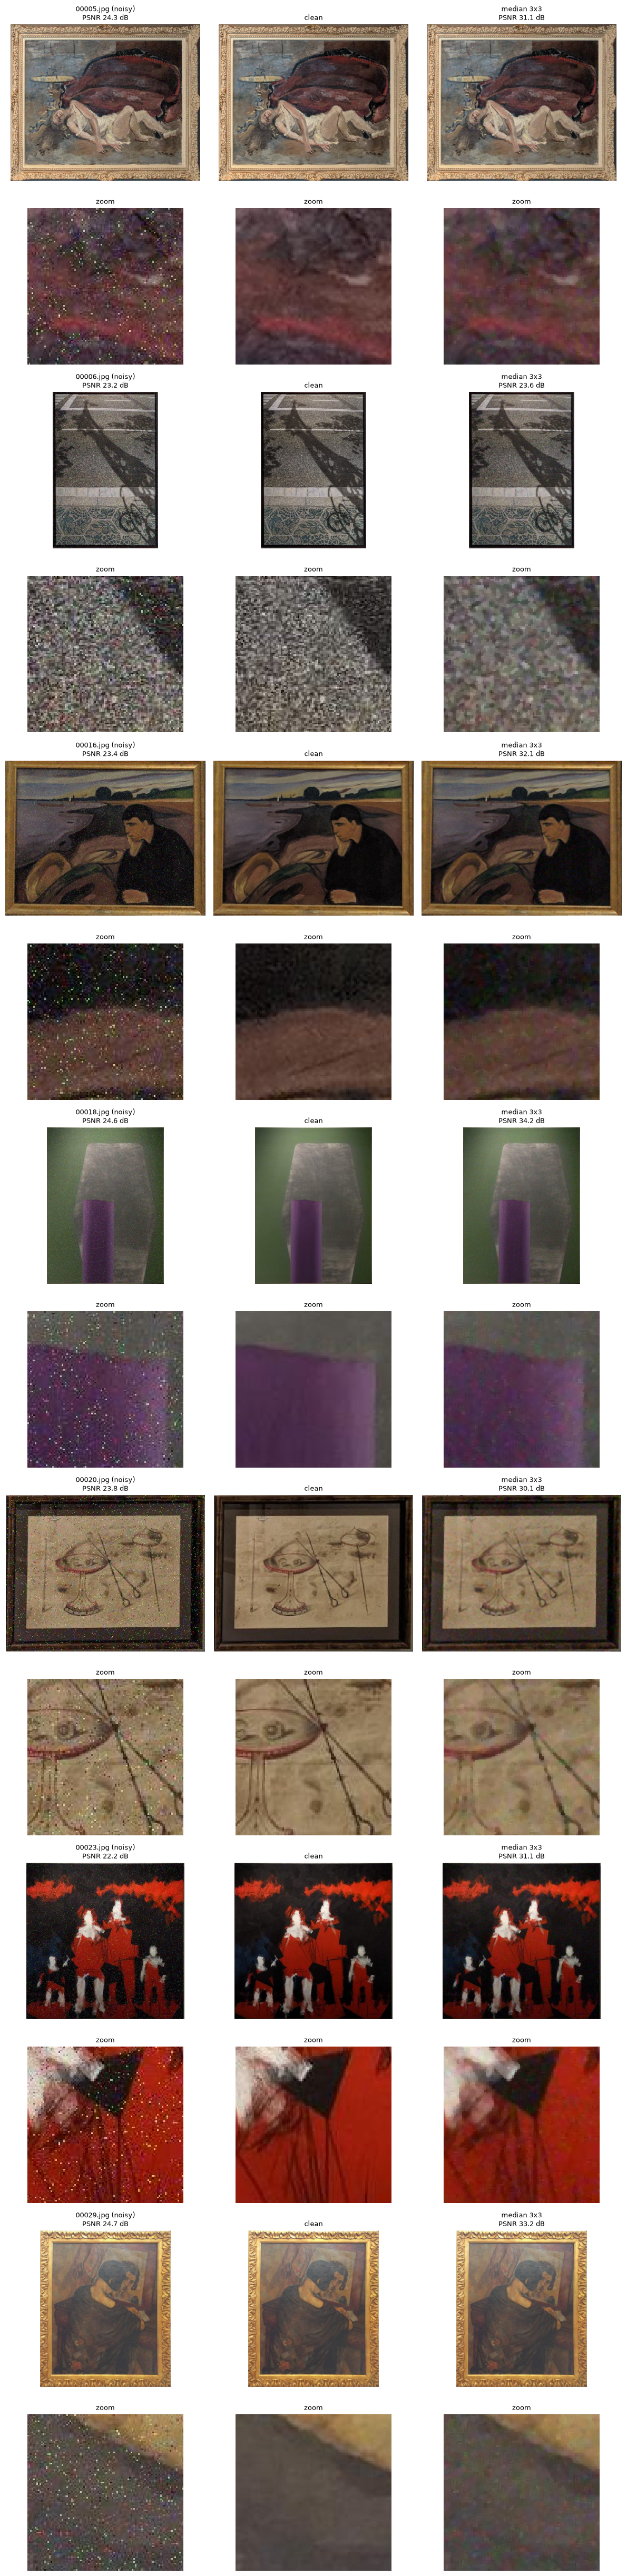

In [11]:
def show_results(indices, save_path=None):
    fig, axes = plt.subplots(2 * len(indices), 3, figsize=(12, 7 * len(indices)), squeeze=False)
    for k, i in enumerate(indices):
        top, bottom = 2 * k, 2 * k + 1
        panels = [(qsd1_imgs[i], f"{qsd1_files[i]} (noisy)\nPSNR {psnr(qsd1_clean[i], qsd1_imgs[i]):.1f} dB"),
                  (qsd1_clean[i], "clean"),
                  (qsd1_denoised[i], f"{BEST_FILTER}\nPSNR {psnr(qsd1_clean[i], qsd1_denoised[i]):.1f} dB")]
        for col, (im, title) in enumerate(panels):
            axes[top, col].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
            axes[top, col].set_title(title, fontsize=9)
            axes[bottom, col].imshow(cv2.cvtColor(zoom(im), cv2.COLOR_BGR2RGB), interpolation="nearest")
            axes[bottom, col].set_title("zoom", fontsize=9)
            axes[top, col].axis("off")
            axes[bottom, col].axis("off")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()

show_results(detected_idx, os.path.join(results_dir, "task1_results.png"))

## TASK 2: Texture descriptors

Retrieval on QSD1-W3 using only texture descriptor. The queries are the denoised ones from Task 1 (`qsd1_denoised`).

In [ ]:
bbdd_path = "./data/BBDD"

bbdd_files = [f for f in os.listdir(bbdd_path) if f.lower().endswith(".jpg")]
bbdd_files.sort(key=return_number)
bbdd_imgs = [read_image(os.path.join(bbdd_path, f)) for f in bbdd_files]
bbdd_ids = np.array([int(re.findall(r"\d+", f)[-1]) for f in bbdd_files]) #bbdd_00012.jpg -> 12
bbdd_index = {b: i for i, b in enumerate(bbdd_ids)} #bbdd id -> position in bbdd_imgs

#ground truth: bbdd id of the painting in every query
with open(os.path.join(qsd1_path, "gt_corresps.pkl"), "rb") as f:
    qsd1_gt = pickle.load(f)
qsd1_gt = [[int(x) for x in g] if isinstance(g, (list, tuple, np.ndarray)) else [int(g)] for g in qsd1_gt]

#type of every query (only used to analyse the results, never to retrieve)
def aug_type(a):
    a = str(a).lower()
    if "noise" in a:
        return "noise"
    if "color" in a or "hue" in a:
        return "color"
    return "none"

qsd1_type = np.array([aug_type(a) for a in qsd1_augs])

print(f"BBDD: {len(bbdd_imgs)} images | QSD1-W3: {len(qsd1_imgs)} queries")
print("query types:", pd.Series(qsd1_type).value_counts().to_dict())
print("raw augmentation labels:", sorted(set(map(str, qsd1_augs)))) 

BBDD: 287 images | QSD1-W3: 30 queries
query types: {'color': 14, 'none': 9, 'noise': 7}
raw augmentation labels: ['None', 'None-MultiplyHue', 'UnnamedImpulseNoise']


### Evaluation metric
map@k: for every query, average precision of the top-k retrieved bbdd ids, then mean over the queries.

In [17]:
def apk(actual, predicted, k=10):
    #average precision at k for one query (actual = list of correct bbdd ids)
    predicted = list(predicted)[:k]
    score, hits = 0.0, 0
    for i, p in enumerate(predicted):
        if p in actual and p not in predicted[:i]:
            hits += 1
            score += hits / (i + 1)
    return score / min(len(actual), k) if actual else 0.0

def mapk(actual, predicted, k=10):
    return np.mean([apk(a, p, k) for a, p in zip(actual, predicted)])

### DCT descriptor

Block-based DCT:

1. Convert the painting to grey level and resize it to 256x256, so every descriptor has the same length.
2. Split it into a grid of `grid x grid` blocks.
3. Compute the 2D DCT of every block.
4. Zig-zag scan the coefficients, from low to high frequencies, and keep the first `N`.
5. Concatenate the `N` coefficients of all the blocks.

Two descriptors are compared with the L1 or L2 distance.

In [18]:
from functools import lru_cache

SIZE = 256 #every image is resized to SIZE x SIZE (blocks of SIZE/grid pixels)

@lru_cache(maxsize=None)
def zigzag_indices(n):
    #(row, col) of an n x n block in zig-zag order: anti-diagonal by anti-diagonal, alternating direction (as in JPEG)
    order = sorted(((i, j) for i in range(n) for j in range(n)),
                   key=lambda p: (p[0] + p[1], p[0] if (p[0] + p[1]) % 2 else p[1]))
    rows, cols = zip(*order)
    return np.array(rows), np.array(cols)

def prepare(img, size=SIZE):
    #grey level, resized and scaled to [0, 1]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return cv2.resize(gray, (size, size), interpolation=cv2.INTER_AREA).astype(np.float32) / 255

def block_dct(gray, grid, n_coefs):
    #first n_coefs (zig-zag) of the 2D DCT of every block -> array (grid * grid, n_coefs)
    b = gray.shape[0] // grid #block side in pixels
    rows, cols = zigzag_indices(b)
    out = []
    for i in range(grid):
        for j in range(grid):
            block = gray[i * b:(i + 1) * b, j * b:(j + 1) * b]
            out.append(cv2.dct(block)[rows[:n_coefs], cols[:n_coefs]])
    return np.array(out)

def dct_descriptor(img, grid=8, n_coefs=10):
    #texture descriptor: concatenation of the first n_coefs of every block
    return block_dct(prepare(img), grid, n_coefs).ravel()

def distance(q, db, metric="L1"):
    #distance between one query descriptor and every row of db
    diff = db - q
    return np.abs(diff).sum(axis=1) if metric == "L1" else np.sqrt((diff ** 2).sum(axis=1))

def retrieve(q_descs, db_descs, metric="L1", k=10):
    #for every query, the k bbdd ids with the smallest distance
    return [bbdd_ids[np.argsort(distance(q, db_descs, metric))[:k]].tolist() for q in q_descs]

### Parameter search on QSD1-W3

Grid search over the number of blocks, the number of coefficients kept per block and the distance. To keep it fast, the DCT of every image is computed only once per grid (with the maximum `N`) and each `N` is just a slice of it.

In [19]:
GRIDS = [2, 4, 8, 16]
NS = [3, 6, 10, 15, 21]
METRICS = ["L1", "L2"]

#grey resized images, computed once
bbdd_gray = [prepare(img) for img in bbdd_imgs]
qsd1_gray = [prepare(img) for img in qsd1_denoised]

rows = []
for grid in GRIDS:
    #zig-zag coefs of all the images for this grid: (n_images, grid * grid, max(NS))
    db_coefs = np.stack([block_dct(g, grid, max(NS)) for g in bbdd_gray])
    q_coefs = np.stack([block_dct(g, grid, max(NS)) for g in qsd1_gray])
    for n in NS:
        db_descs = db_coefs[:, :, :n].reshape(len(db_coefs), -1)
        q_descs = q_coefs[:, :, :n].reshape(len(q_coefs), -1)
        for metric in METRICS:
            preds = retrieve(q_descs, db_descs, metric)
            rows.append({"grid": f"{grid}x{grid}", "N": n, "metric": metric, "dim": grid * grid * n,
                         "map@1": mapk(qsd1_gt, preds, 1), "map@5": mapk(qsd1_gt, preds, 5)})

#sanity check: slicing the cache gives the same descriptor as dct_descriptor()
assert np.allclose(q_descs[0], dct_descriptor(qsd1_denoised[0], grid, n))

#best first; on a tie, the shortest descriptor
df_dct = pd.DataFrame(rows).sort_values(["map@1", "map@5", "dim"], ascending=[False, False, True]).reset_index(drop=True)
df_dct.to_csv(os.path.join(results_dir, "task2_dct_grid_search.csv"), index=False)
display(df_dct.head(10).round(3))

best = df_dct.iloc[0]
DCT_PARAMS = dict(grid=int(best["grid"].split("x")[0]), n_coefs=int(best["N"]))
DCT_METRIC = best["metric"]
print("Best:", DCT_PARAMS, DCT_METRIC)

,grid,N,metric,dim,map@1,map@5
0,4x4,21,L1,336,0.933,0.933
1,4x4,15,L1,240,0.900,0.917
2,2x2,15,L1,60,0.900,0.911
3,2x2,21,L1,84,0.900,0.911
4,8x8,15,L1,960,0.900,0.907
5,8x8,21,L1,1344,0.900,0.907
6,8x8,6,L1,384,0.900,0.900
7,8x8,10,L1,640,0.900,0.900
8,4x4,10,L1,160,0.867,0.890
9,16x16,6,L1,1536,0.867,0.878


Best: {'grid': 4, 'n_coefs': 21} L1


The best configuration is a 4x4 grid with N = 21 coefficients per block and L1 distance (336 dims), with map@1 = 0.933 and map@5 = 0.933 (28 of the 30 queries retrieved at rank 1).

- L1 is consistently better than L2: all the top-10 configurations use L1. L2 squares the differences, so a few blocks that differ a lot dominate the distance.
- The descriptor is robust to the grid size: 2x2, 4x4 and 8x8 all reach map@1 = 0.900 with enough coefficients. Only the finest grid (16x16, blocks of 16 px) is clearly worse, since small blocks are more sensitive to small misalignments of the crop and to residual noise.
- More coefficients help slightly: with the 4x4 grid, map@1 goes from 0.867 (N = 10) to 0.900 (N = 15) and 0.933 (N = 21).

The differences between the best configurations are small: with 30 queries, one query more or less changes map@1 by 0.033.

### Results with the best configuration

In [20]:
db_descs = np.stack([dct_descriptor(img, **DCT_PARAMS) for img in bbdd_imgs])
q_descs = np.stack([dct_descriptor(img, **DCT_PARAMS) for img in qsd1_denoised])
qsd1_dct_preds = retrieve(q_descs, db_descs, DCT_METRIC)

#quantitative: map@k on all the queries and by type of query
rows = []
for name, idx in [("all", np.arange(len(qsd1_gt)))] + [(t, np.where(qsd1_type == t)[0]) for t in sorted(set(qsd1_type))]:
    gt, preds = [qsd1_gt[i] for i in idx], [qsd1_dct_preds[i] for i in idx]
    rows.append({"queries": name, "count": len(idx), "map@1": mapk(gt, preds, 1), "map@5": mapk(gt, preds, 5)})

df_dct_results = pd.DataFrame(rows)
df_dct_results.to_csv(os.path.join(results_dir, "task2_dct_results.csv"), index=False)
print(f"DCT: grid {DCT_PARAMS['grid']}x{DCT_PARAMS['grid']}, N={DCT_PARAMS['n_coefs']}, {DCT_METRIC} "
      f"-> {DCT_PARAMS['grid'] ** 2 * DCT_PARAMS['n_coefs']} dims")
display(df_dct_results.round(3))

DCT: grid 4x4, N=21, L1 -> 336 dims


,queries,count,map@1,map@5
0,all,30,0.933,0.933
1,color,14,0.857,0.857
2,noise,7,1.000,1.000
3,none,9,1.000,1.000


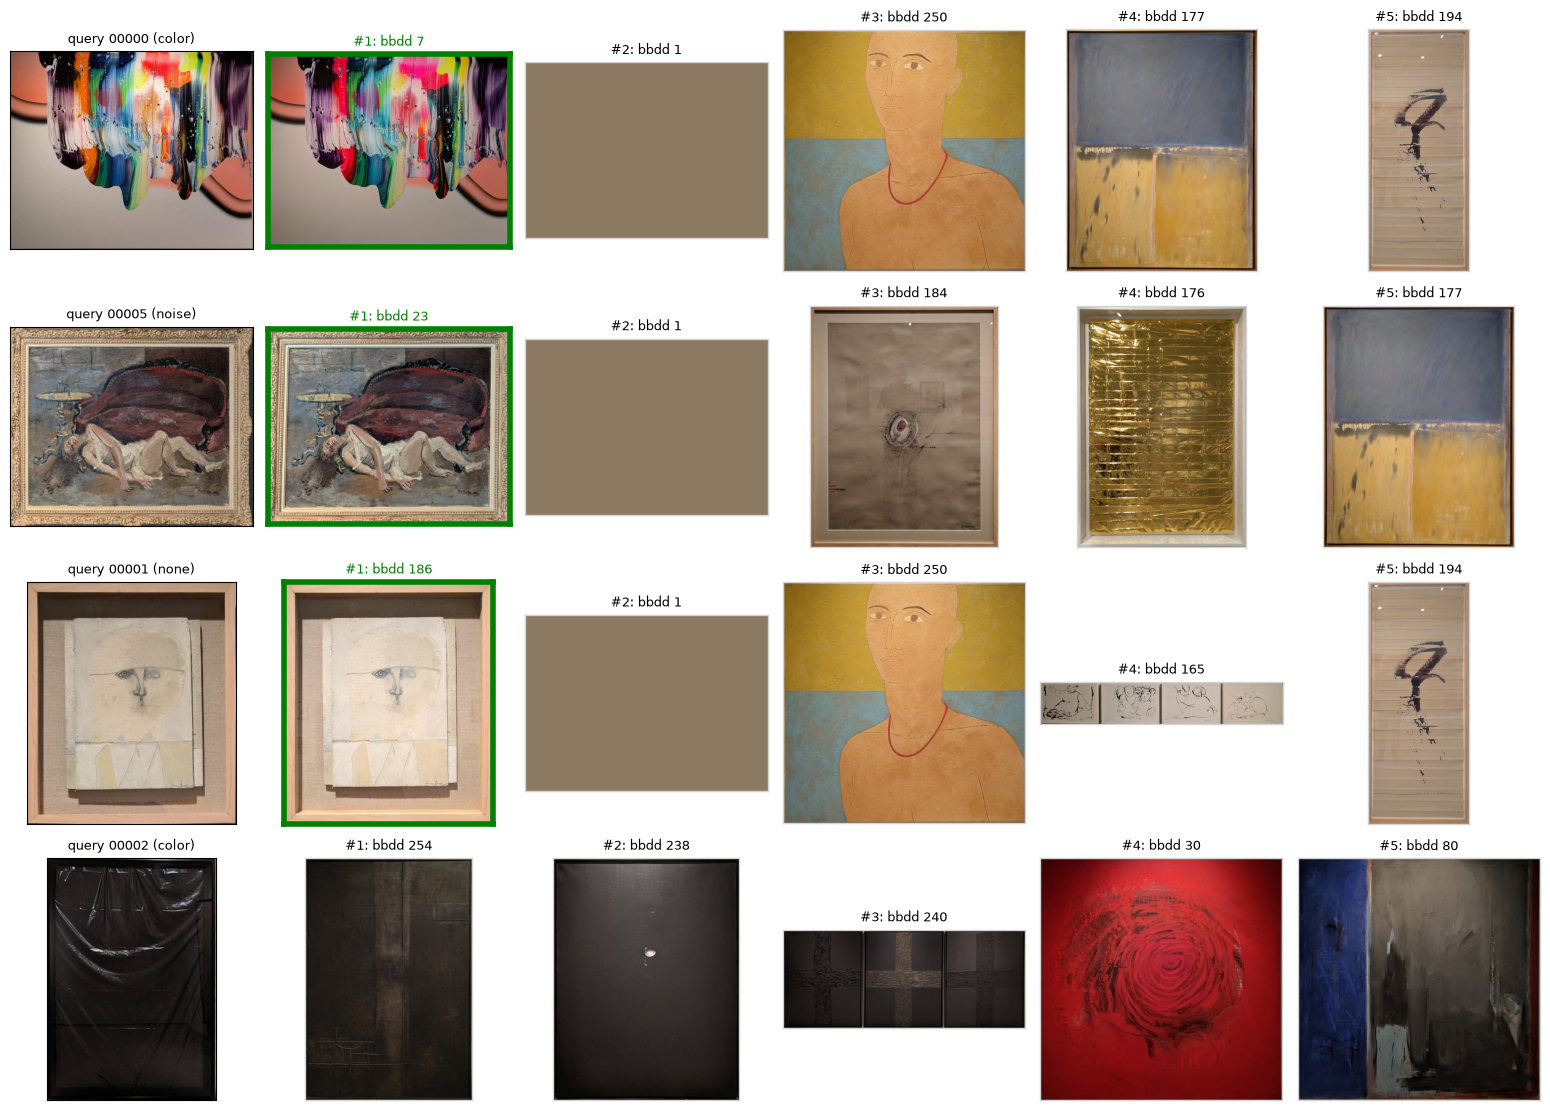

In [21]:
def show_retrieval(indices, preds, top=5, save_path=None):
    #query + its top retrieved paintings; green = correct painting
    fig, axes = plt.subplots(len(indices), top + 1, figsize=(2.6 * (top + 1), 2.8 * len(indices)), squeeze=False)
    for r, i in enumerate(indices):
        axes[r, 0].imshow(cv2.cvtColor(qsd1_imgs[i], cv2.COLOR_BGR2RGB))
        axes[r, 0].set_title(f"query {qsd1_files[i][:-4]} ({qsd1_type[i]})", fontsize=9)
        for k, bid in enumerate(preds[i][:top]):
            ok = bid in qsd1_gt[i]
            ax = axes[r, k + 1]
            ax.imshow(cv2.cvtColor(bbdd_imgs[bbdd_index[bid]], cv2.COLOR_BGR2RGB))
            ax.set_title(f"#{k + 1}: bbdd {bid}", fontsize=9, color="g" if ok else "k")
            for s in ax.spines.values():
                s.set_edgecolor("g" if ok else "lightgrey")
                s.set_linewidth(4 if ok else 1)
        for ax in axes[r]:
            ax.set_xticks([])
            ax.set_yticks([])
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()

#qualitative: one query of each type and, if there is any, one failure (rank 1 wrong)
chosen = [np.where(qsd1_type == t)[0][0] for t in sorted(set(qsd1_type))]
fails = [i for i, (p, g) in enumerate(zip(qsd1_dct_preds, qsd1_gt)) if p[0] not in g and i not in chosen]
show_retrieval(chosen + fails[:1], qsd1_dct_preds, save_path=os.path.join(results_dir, "task2_dct_examples.png"))

With the best configuration (4x4 grid, N = 21, L1, 336 dims) the DCT descriptor reaches map@1 = 0.933 and map@5 = 0.933 on QSD1-W3: 28 of the 30 queries are retrieved at rank 1, and the 2 failures do not appear in the top-5 either.

- Noisy queries (7/7) and clean queries (9/9) are all retrieved at rank 1. The median filter of Task 1 removes the impulse noise before the DCT, so it does not reach the high-frequency coefficients.
- Both failures are colour-changed queries (map@1 = 0.857, 12/14). The descriptor works on the grey level, but a hue change also changes the grey values, and the DC coefficient (mean brightness of each block) changes with them.
- The failures are dark paintings with little texture (e.g. query 00002): almost all the information is in the DC and the low frequencies, so the top-5 are other dark, flat paintings with a similar layout.
- bbdd 1, a uniform brown image, appears at rank 2 in several queries. It has no texture (all its AC coefficients are ≈ 0), so it is at a moderate distance from every query. It never overtakes the correct painting, but it shows the main limitation of a texture-only descriptor: paintings with little texture are hard to tell apart.

Step by step example of the DCT descriptor on one query (same parameters as the final configuration)


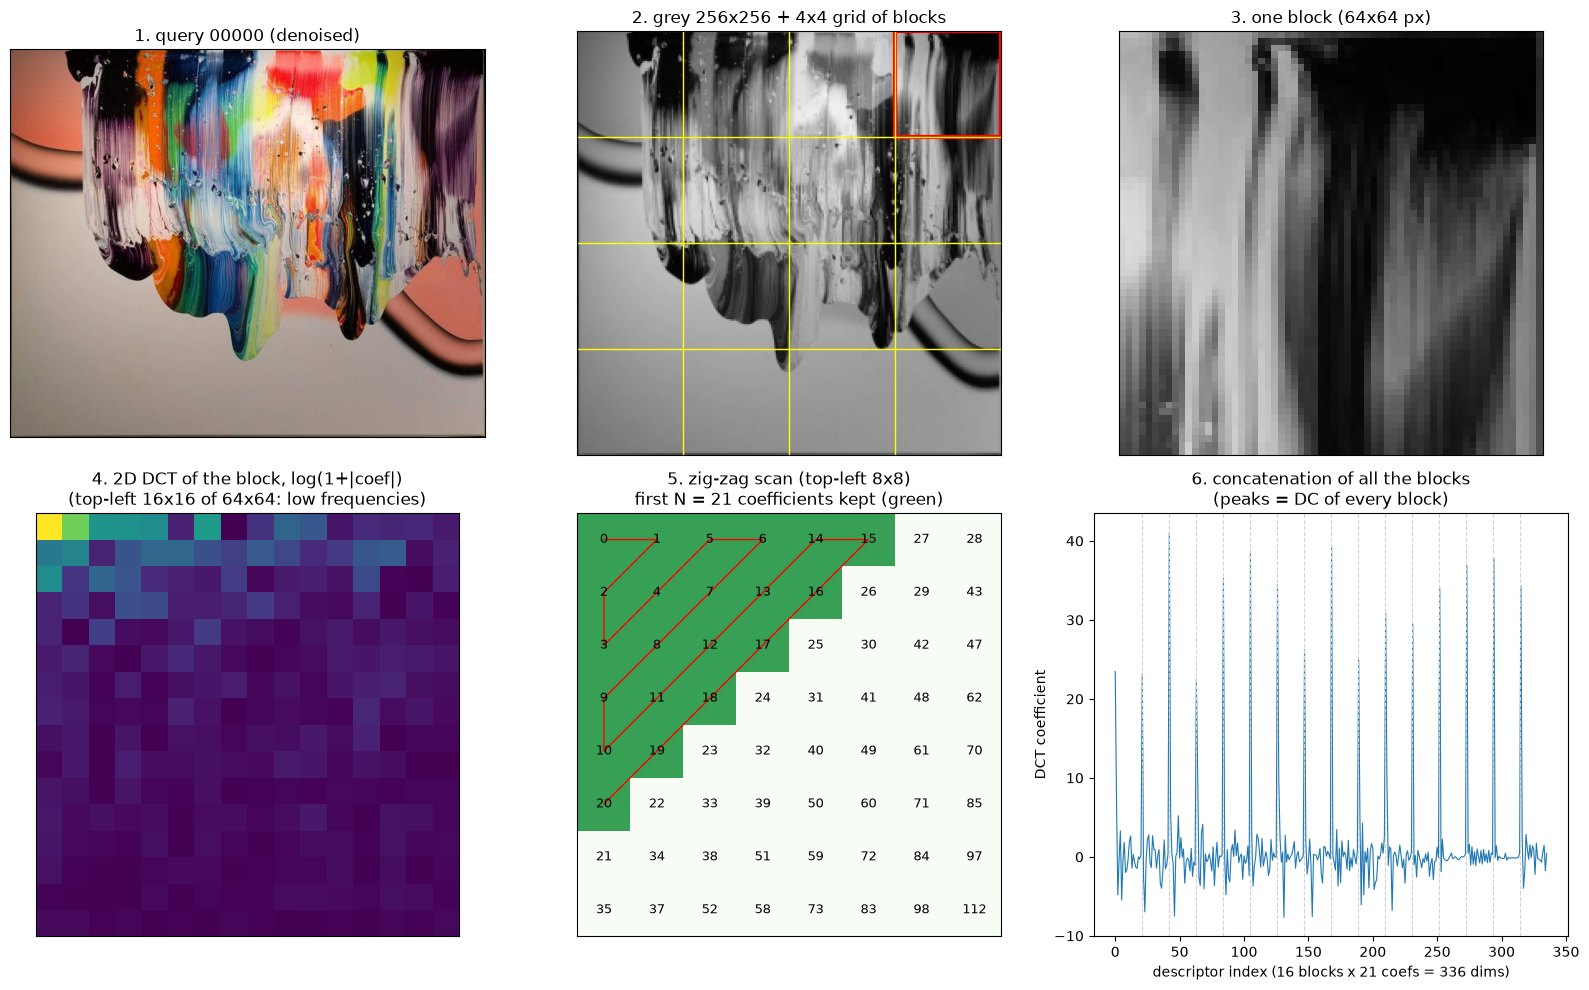

In [22]:
EX_QUERY, EX_GRID, EX_N = 0, 4, 21

img = qsd1_denoised[EX_QUERY]
gray = prepare(img)
b = SIZE // EX_GRID #block side in pixels

#block to show: the most textured one (highest std), just to have a clear example
stds = gray.reshape(EX_GRID, b, EX_GRID, b).std(axis=(1, 3))
bi, bj = np.unravel_index(np.argmax(stds), stds.shape)
block = gray[bi * b:(bi + 1) * b, bj * b:(bj + 1) * b]
coefs = cv2.dct(np.ascontiguousarray(block))

#zig-zag position of every coefficient
rows, cols = zigzag_indices(b)
order = np.zeros((b, b), int)
order[rows, cols] = np.arange(b * b)

desc = dct_descriptor(img, EX_GRID, EX_N)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
ax = axes.flat

ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
ax[0].set_title(f"1. query {qsd1_files[EX_QUERY][:-4]} (denoised)")

ax[1].imshow(gray, cmap="gray", vmin=0, vmax=1)
for k in range(1, EX_GRID):
    ax[1].axhline(k * b - 0.5, c="yellow", lw=1)
    ax[1].axvline(k * b - 0.5, c="yellow", lw=1)
ax[1].add_patch(plt.Rectangle((bj * b - 0.5, bi * b - 0.5), b, b, fill=False, ec="r", lw=3))
ax[1].set_title(f"2. grey {SIZE}x{SIZE} + {EX_GRID}x{EX_GRID} grid of blocks")

ax[2].imshow(block, cmap="gray", vmin=0, vmax=1)
ax[2].set_title(f"3. one block ({b}x{b} px)")

ZOOM = 16 #only the top-left corner, where the energy is
ax[3].imshow(np.log1p(np.abs(coefs[:ZOOM, :ZOOM])), cmap="viridis")
ax[3].set_title(f"4. 2D DCT of the block, log(1+|coef|)\n(top-left {ZOOM}x{ZOOM} of {b}x{b}: low frequencies)")

corner = order[:8, :8]
ax[4].imshow(corner < EX_N, cmap="Greens", vmin=0, vmax=1.5)
for (r, c), v in np.ndenumerate(corner):
    ax[4].text(c, r, v, ha="center", va="center", fontsize=9)
ax[4].plot(cols[:EX_N], rows[:EX_N], "r-", lw=1)
ax[4].set_title(f"5. zig-zag scan (top-left 8x8)\nfirst N = {EX_N} coefficients kept (green)")

for a in ax[:5]:
    a.set_xticks([])
    a.set_yticks([])

ax[5].plot(desc, lw=0.8)
for k in range(1, EX_GRID * EX_GRID):
    ax[5].axvline(k * EX_N - 0.5, c="lightgrey", ls="--", lw=0.8)
ax[5].set_xlabel(f"descriptor index ({EX_GRID * EX_GRID} blocks x {EX_N} coefs = {desc.size} dims)")
ax[5].set_ylabel("DCT coefficient")
ax[5].set_title("6. concatenation of all the blocks\n(peaks = DC of every block)")

plt.tight_layout()
plt.savefig(os.path.join(results_dir, "task2_dct_pipeline.png"), dpi=120, bbox_inches="tight")
plt.show()